# ***GrapeVine Proj***
----
### **1. Imports**

In [11]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import os
import shutil
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset
from sklearn.model_selection import train_test_split
import sys
import numpy as np
from tqdm.auto import tqdm
import torch.nn.functional as F

from torchcam.methods import GradCAM
import random
from PIL import Image

if not hasattr(torch, "_six"):
    from unittest.mock import MagicMock
    mock = MagicMock()
    mock.string_classes = (str, bytes)
    torch._six = mock
    sys.modules["torch._six"] = mock

In [12]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

### **2. Load MobileNet V2**

In [13]:
model = torch.hub.load('pytorch/vision:v0.10.0', 'mobilenet_v2', pretrained=True)
model = model.to(device)
model.eval()

Using cache found in C:\Users\xared/.cache\torch\hub\pytorch_vision_v0.10.0
c:\Users\xared\AppData\Local\Programs\Python\Python311\Lib\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
c:\Users\xared\AppData\Local\Programs\Python\Python311\Lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=MobileNet_V2_Weights.IMAGENET1K_V1`. You can also use `weights=MobileNet_V2_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


MobileNetV2(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU6(inplace=True)
    )
    (1): InvertedResidual(
      (conv): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
          (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
          (2): ReLU6(inplace=True)
        )
        (1): Conv2d(32, 16, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (2): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      )
    )
    (2): InvertedResidual(
      (conv): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(16, 96, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (1): BatchNorm2d(96, eps=

### **3. Load Dataset**

In [ ]:
proccessedRoot = "../0_data/augmented-dataset/"

train_transform = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.6, 1.0)),  # forces focus on partial views
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3, hue=0.1),
    transforms.RandomGrayscale(p=0.1),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Load train and test directly
full_train = datasets.ImageFolder(root=os.path.join(proccessedRoot, "train"), transform=transform)
test_dataset = datasets.ImageFolder(root=os.path.join(proccessedRoot, "test"), transform=transform)

# Carve 10% val out of train (stratified)
indices = list(range(len(full_train)))
train_idx, val_idx = train_test_split(
    indices, test_size=0.1, stratify=full_train.targets, random_state=42
)

train_dataset = Subset(full_train, train_idx)
val_dataset   = Subset(full_train, val_idx)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True,  num_workers=0)
val_loader   = DataLoader(val_dataset,   batch_size=32, shuffle=False, num_workers=0)
test_loader  = DataLoader(test_dataset,  batch_size=32, shuffle=False, num_workers=0)

class_names = full_train.classes
print(f"Classes: {class_names}")
print(f"Train: {len(train_dataset)} | Val: {len(val_dataset)} | Test: {len(test_dataset)}")

Classes: ['Black Rot', 'ESCA', 'Healthy', 'Leaf Blight']
Train: 12999 | Val: 1445 | Test: 3610


In [15]:
# Example: Grab one batch to check shapes
images, labels = next(iter(train_loader))
print(f"Batch Image Shape: {images.shape}") # Should be [32, 3, 224, 224]
print(f"Batch Label Shape: {labels.shape}") # Should be [32]

Batch Image Shape: torch.Size([32, 3, 224, 224])
Batch Label Shape: torch.Size([32])


In [16]:
from collections import Counter

# Get counts from the actual new dataset
label_counts = Counter([full_train.targets[i] for i in train_idx])
class_counts = [label_counts[i] for i in range(len(full_train.classes))]

print(f"Class names:  {full_train.classes}")
print(f"Class counts: {dict(zip(full_train.classes, class_counts))}")

# Weights
total_samples = sum(class_counts)
num_classes = len(class_counts)
weights = [total_samples / (num_classes * count) for count in class_counts]
class_weights = torch.tensor(weights, dtype=torch.float).to(device)
print(f"Calculated Weights: {class_weights}")

criterion = nn.CrossEntropyLoss(weight=class_weights)

Class names:  ['Black Rot', 'ESCA', 'Healthy', 'Leaf Blight']
Class counts: {'Black Rot': 3398, 'ESCA': 3456, 'Healthy': 3046, 'Leaf Blight': 3099}
Calculated Weights: tensor([0.9564, 0.9403, 1.0669, 1.0486], device='cuda:0')


In [17]:
# 1. Replace the 1000-class head with a 4-class head
# MobileNetV2 stores its final layer in model.classifier[1]
model.classifier[1] = nn.Linear(model.last_channel, 4)

# 2. Move the updated model back to GPU
model = model.to(device)

# 3. Set to train mode (since we are about to start training)
model.train()

print(f"Classifier updated for 4 classes. Ready for training.")

Classifier updated for 4 classes. Ready for training.


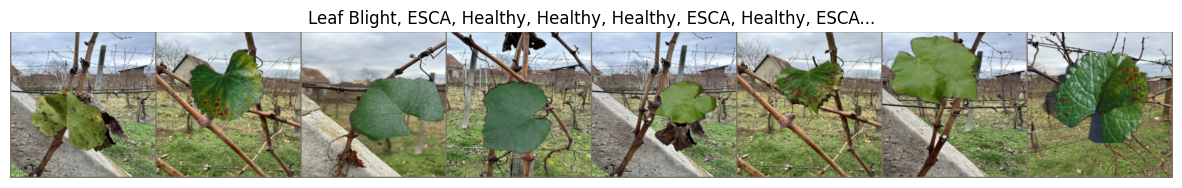

In [18]:
# Visulize a batch of images and their corresponding labels
import matplotlib.pyplot as plt
def imshow(inp, title=None):
    """Display image for Tensor."""
    # Convert from Tensor [C, H, W] to numpy [H, W, C]
    inp = inp.numpy().transpose((1, 2, 0))
    
    # Revert the normalization for visualization
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    inp = std * inp + mean
    
    # Clip values to stay in [0, 1] range
    inp = np.clip(inp, 0, 1)
    
    plt.figure(figsize=(15, 10))
    plt.imshow(inp)
    if title is not None:
        # Join titles with a space or limit the number shown for readability
        plt.title(", ".join(title[:8]) + "...") 
    plt.axis('off') # Hide axes
    plt.show()

# 1. Grab a batch from YOUR train_loader
inputs, labels = next(iter(train_loader))

# 2. Make a grid from the first 8 images (so the title is readable)
out = torchvision.utils.make_grid(inputs[:8])

# 3. Use your class_names list to map the integer labels back to text
imshow(out, title=[full_train.classes[x] for x in labels[:8]])

In [19]:
# Freeze all backbone parameters
for param in model.features.parameters():
    param.requires_grad = False

# The head is already unfrozen (requires_grad=True by default)
# Only pass the head's parameters to the optimizer
optimizer = torch.optim.AdamW(model.classifier.parameters(), lr=1e-3)

In [20]:
# This helps the model settle into the best Recall values 
# by slowing down the learning rate as it gets closer to the solution.
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=10, eta_min=1e-6)

print("Backbone frozen. Optimizer and scheduler set up for head training.")

# train with recall as the metric to optimize for.
def train_one_epoch(model, dataloader, criterion, optimizer, device):
    model.train()
    running_loss = 0.0
    all_preds = []
    all_labels = []
    pbar = tqdm(dataloader, desc="Training", leave=False)
    for i, (inputs, labels) in enumerate(dataloader):
        inputs, labels = inputs.to(device), labels.to(device)
        
        optimizer.zero_grad()
        
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item() * inputs.size(0)
        
        _, preds = torch.max(outputs, 1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())
        if (i + 1) % 10 == 0:  # Print every 10 batches
            pbar.update(10)
            pbar.set_postfix({"Loss": f"{loss.item():.4f}"})
            pbar.set_postfix_str(f"recall score: {recall_score(all_labels, all_preds, average='macro'):.4f}")            
    
    epoch_loss = running_loss / len(dataloader.dataset)
    return epoch_loss, all_preds, all_labels
from sklearn.metrics import recall_score
def evaluate(model, dataloader, criterion, device):
    model.eval()
    running_loss = 0.0
    all_preds = []
    all_labels = []
    pbar = tqdm(dataloader, desc="Evaluating", leave=False)
    with torch.no_grad():
        for i, (inputs, labels) in enumerate(dataloader):
            inputs, labels = inputs.to(device), labels.to(device)
            
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            running_loss += loss.item() * inputs.size(0)
            
            _, preds = torch.max(outputs, 1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            if (i + 1) % 10 == 0:  # Print every 10 batches
                pbar.update(10)
                pbar.set_postfix({"Loss": f"{loss.item():.4f}"})
                pbar.set_postfix_str(f"recall score: {recall_score(all_labels, all_preds, average='macro'):.4f}")
                                
    epoch_loss = running_loss / len(dataloader.dataset)
    recall = recall_score(all_labels, all_preds, average='macro')
    return epoch_loss, recall
num_epochs = 10
best_recall = 0.0
for epoch in range(num_epochs):
    train_loss, _, _ = train_one_epoch(model, train_loader, criterion, optimizer, device)
    val_loss, val_recall = evaluate(model, val_loader, criterion, device)
    
    print(f"Epoch {epoch+1}/{num_epochs} | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | Val Recall: {val_recall:.4f}")
    
    # Save the best model based on validation recall
    if val_recall > best_recall:
        best_recall = val_recall
        torch.save(model.state_dict(), "best_model.pth")
        print("Best model saved with recall: {:.4f}".format(best_recall))
    
    scheduler.step()

Backbone frozen. Optimizer and scheduler set up for head training.


Training:   0%|          | 0/407 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/46 [00:00<?, ?it/s]

Epoch 1/10 | Train Loss: 0.6225 | Val Loss: 0.4191 | Val Recall: 0.8350
Best model saved with recall: 0.8350


Training:   0%|          | 0/407 [00:00<?, ?it/s]

...

Evaluating:   0%|          | 0/46 [00:00<?, ?it/s]

Epoch 9/10 | Train Loss: 0.3231 | Val Loss: 0.2848 | Val Recall: 0.8857


Training:   0%|          | 0/407 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/46 [00:00<?, ?it/s]

Epoch 10/10 | Train Loss: 0.3073 | Val Loss: 0.2825 | Val Recall: 0.8904
Best model saved with recall: 0.8904


In [26]:
val_preds = []
val_labels = []
# Nuclear option: reload model state to clear all hooks
model = torch.hub.load('pytorch/vision:v0.10.0', 'mobilenet_v2', pretrained=False)
model.classifier[1] = nn.Linear(model.last_channel, 4)
model.load_state_dict(torch.load("best_model.pth", map_location=device))
model = model.to(device)
model.eval()
model.eval()
with torch.no_grad():
    for inputs, labels in val_loader:
        inputs = inputs.to(device)
        outputs = model(inputs)
        _, preds = torch.max(outputs, 1)
        
        val_preds.extend(preds.cpu().numpy())
        val_labels.extend(labels.cpu().numpy())

print("Data captured for Confusion Matrix.")

Using cache found in C:\Users\xared/.cache\torch\hub\pytorch_vision_v0.10.0
c:\Users\xared\AppData\Local\Programs\Python\Python311\Lib\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
c:\Users\xared\AppData\Local\Programs\Python\Python311\Lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)
C:\Users\xared\AppData\Local\Temp\ipykernel_28296\3843522586.py:6: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/py

Data captured for Confusion Matrix.


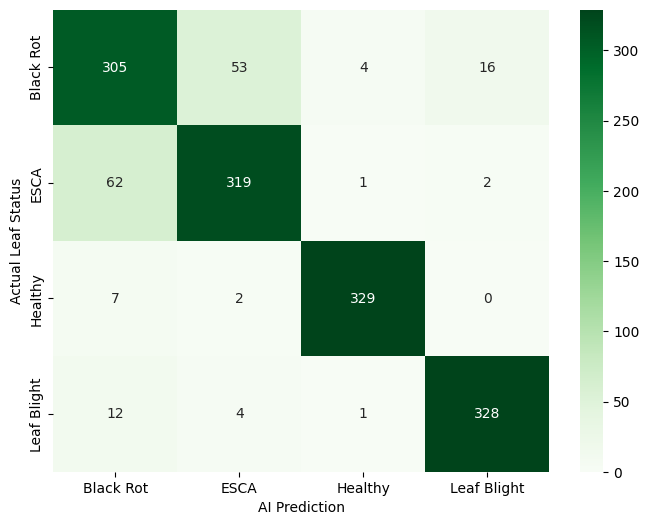

              precision    recall  f1-score   support

   Black Rot       0.79      0.81      0.80       378
        ESCA       0.84      0.83      0.84       384
     Healthy       0.98      0.97      0.98       338
 Leaf Blight       0.95      0.95      0.95       345

    accuracy                           0.89      1445
   macro avg       0.89      0.89      0.89      1445
weighted avg       0.89      0.89      0.89      1445



In [27]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

# The Matrix
cm = confusion_matrix(val_labels, val_preds)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', 
            xticklabels=full_train.classes, 
            yticklabels=full_train.classes)
plt.ylabel('Actual Leaf Status')
plt.xlabel('AI Prediction')
plt.show()

# The Text Report (This is the one that proves your 99.46% Recall)
print(classification_report(val_labels, val_preds, target_names=full_train.classes))

### TEST : OVERCONFIDENCE 

In [28]:
model.eval()
mismatched_images = []

with torch.no_grad():
    for inputs, labels in val_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = model(inputs)
        probs = F.softmax(outputs, dim=1)
        _, preds = torch.max(outputs, 1)
        
        # Find where it messed up
        mask = preds != labels
        if mask.any():
            for i in range(len(mask)):
                if mask[i]:
                    # Print the probability spread for the error
                    print(f"Actual: {full_train.classes[labels[i]]}")
                    print(f"Probabilities: {dict(zip(full_train.classes, probs[i].cpu().numpy()))}")
                    print("-" * 30)

# If the dict shows 'esca': 0.48 and 'black_rot': 0.51, your model is fine.
# If it shows 'esca': 0.01 and 'black_rot': 0.98, the model is "lying" to itself.

Actual: Black Rot
Probabilities: {'Black Rot': 0.39197633, 'ESCA': 0.5742466, 'Healthy': 0.0039695194, 'Leaf Blight': 0.029807536}
------------------------------
Actual: Leaf Blight
Probabilities: {'Black Rot': 0.51851207, 'ESCA': 0.00859333, 'Healthy': 0.00046333182, 'Leaf Blight': 0.47243124}
------------------------------
Actual: Black Rot
Probabilities: {'Black Rot': 0.43773946, 'ESCA': 0.55986136, 'Healthy': 0.0010161818, 'Leaf Blight': 0.0013829868}
------------------------------
Actual: Black Rot
Probabilities: {'Black Rot': 0.24706171, 'ESCA': 0.0055824392, 'Healthy': 0.0066811815, 'Leaf Blight': 0.7406747}
------------------------------
Actual: ESCA
Probabilities: {'Black Rot': 0.49967274, 'ESCA': 0.48638928, 'Healthy': 0.0069217714, 'Leaf Blight': 0.0070162327}
------------------------------
Actual: Leaf Blight
Probabilities: {'Black Rot': 0.1623132, 'ESCA': 0.5457748, 'Healthy': 0.064972535, 'Leaf Blight': 0.2269395}
------------------------------
Actual: Black Rot
Probabili

### GRADCAM 

In [33]:
# 1. Unfreeze the entire model (Backbone + Head)
for param in model.parameters():
    param.requires_grad = True

# 2. Lower the Learning Rate significantly (The 'Surgical' LR)
# Previous was 1e-3, now we use 1e-5
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-5)
num_epochs_p2 = 10  # give it more room than 5, the problem is hard
# 3. Optional: Reset the scheduler for a fresh start
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=num_epochs_p2, eta_min=1e-7)
print("Backbone UNFROZEN. Transitioning to Phase 2: Fine-Tuning.")


Backbone UNFROZEN. Transitioning to Phase 2: Fine-Tuning.


In [36]:
# Clean reload
model = torch.hub.load('pytorch/vision:v0.10.0', 'mobilenet_v2', pretrained=False)
model.classifier[1] = nn.Linear(model.last_channel, 4)
model.load_state_dict(torch.load("best_model.pth", map_location=device))
model = model.to(device)

# Unfreeze everything
for param in model.parameters():
    param.requires_grad = True

# Phase 2
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-5, weight_decay=1e-4)
num_epochs_p2 = 10
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=num_epochs_p2, eta_min=1e-7)

best_recall_p2 = 0.0
for epoch in range(num_epochs_p2):
    train_loss, _, _ = train_one_epoch(model, train_loader, criterion, optimizer, device)
    val_loss, val_recall = evaluate(model, val_loader, criterion, device)
    
    print(f"Phase 2 - Epoch {epoch+1}/{num_epochs_p2} | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | Val Recall: {val_recall:.4f}")
    
    if val_recall > best_recall_p2:
        best_recall_p2 = val_recall
        torch.save(model.state_dict(), "../4_models/agroStake-0.2-p2.pth")
        print(f"Best model saved: {best_recall_p2:.4f}")
    
    scheduler.step()

Using cache found in C:\Users\xared/.cache\torch\hub\pytorch_vision_v0.10.0
c:\Users\xared\AppData\Local\Programs\Python\Python311\Lib\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
c:\Users\xared\AppData\Local\Programs\Python\Python311\Lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)
C:\Users\xared\AppData\Local\Temp\ipykernel_28296\43750703.py:4: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pyto

Training:   0%|          | 0/407 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/46 [00:00<?, ?it/s]

Phase 2 - Epoch 1/10 | Train Loss: 0.1875 | Val Loss: 0.1320 | Val Recall: 0.9464
Best model saved: 0.9464


Training:   0%|          | 0/407 [00:00<?, ?it/s]

...

Evaluating:   0%|          | 0/46 [00:00<?, ?it/s]

Phase 2 - Epoch 9/10 | Train Loss: 0.0177 | Val Loss: 0.0646 | Val Recall: 0.9813
Best model saved: 0.9813


Training:   0%|          | 0/407 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/46 [00:00<?, ?it/s]

Phase 2 - Epoch 10/10 | Train Loss: 0.0164 | Val Loss: 0.0646 | Val Recall: 0.9820
Best model saved: 0.9820


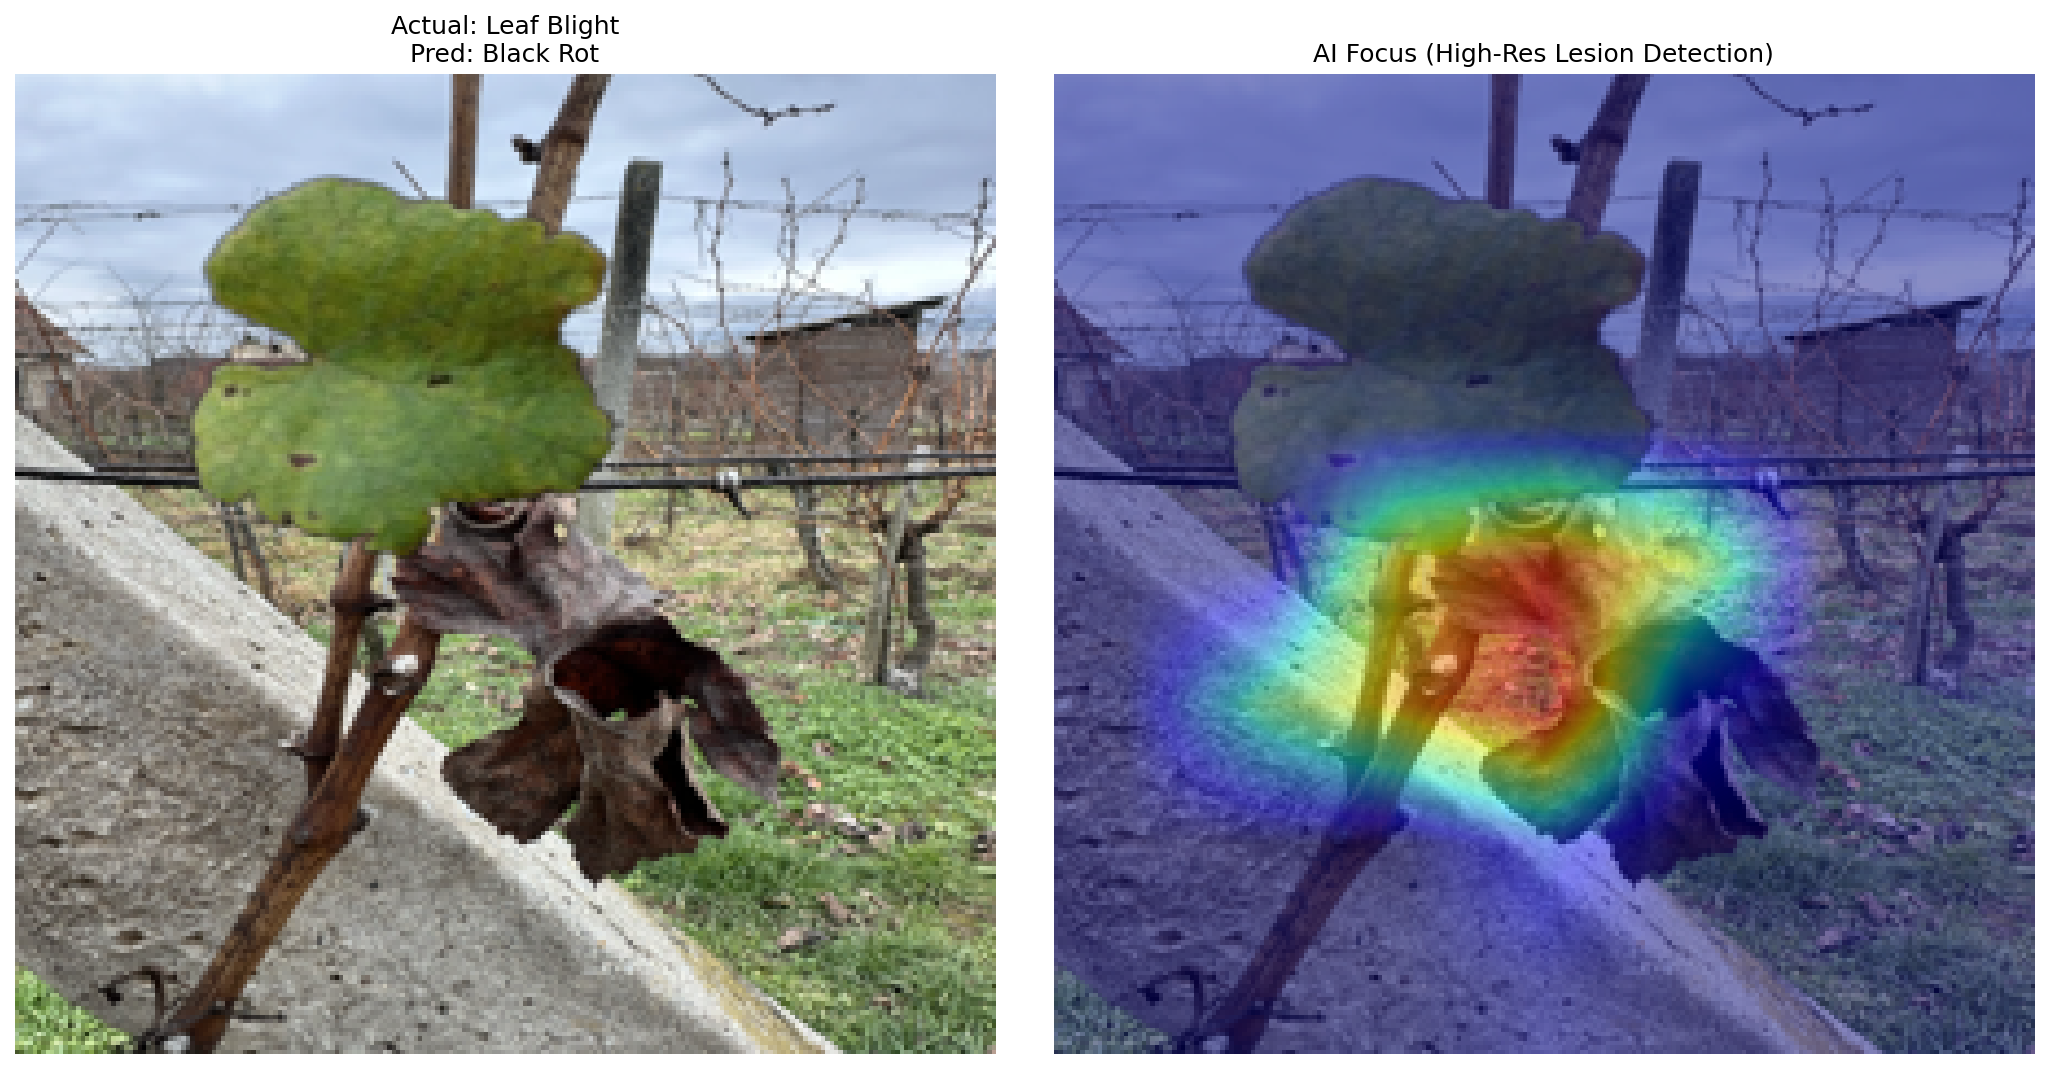

In [75]:
def visualize_model_focus_high_res(model, dataset, device):
    model.train() 
    cam_extractor = GradCAM(model, target_layer='features')

    # 1. Grab random sample
    idx = random.randint(0, len(dataset) - 1)
    img_path, label = dataset.samples[idx]
    img_tensor, _ = dataset[idx]
    
    # 2. Prepare Input
    input_tensor = img_tensor.unsqueeze(0).to(device)
    input_tensor.requires_grad_(True) 
    for param in model.features.parameters():
        param.requires_grad = True

    # 3. Forward pass
    out = model(input_tensor)
    pred_idx = out.squeeze(0).argmax().item()
    activation_map = cam_extractor(pred_idx, out)
    
    # 4. Clean up hooks and Re-freeze
    cam_extractor.remove_hooks()
    for param in model.features.parameters():
        param.requires_grad = False
    model.eval()

    # 5. HIGH-RES INTERPOLATION
    # Convert activation map to tensor for interpolation
    raw_heatmap = activation_map[0].squeeze(0).unsqueeze(0).unsqueeze(0) 
    
    # Scale up the 7x7 heatmap to 224x224 using Bilinear Interpolation
    hi_res_heatmap = F.interpolate(raw_heatmap, size=(224, 224), mode='bilinear', align_corners=False)
    hi_res_heatmap = hi_res_heatmap.squeeze().cpu().numpy()

    # 6. Normalize
    hi_res_heatmap = (hi_res_heatmap - hi_res_heatmap.min()) / (hi_res_heatmap.max() - hi_res_heatmap.min() + 1e-8)

    # 7. Plotting with High DPI
    raw_img = Image.open(img_path).convert('RGB').resize((224, 224))
    
    plt.figure(figsize=(14, 7), dpi=150) # Higher DPI for better resolution
    
    plt.subplot(1, 2, 1)
    plt.imshow(raw_img)
    plt.title(f"Actual: {dataset.classes[label]}\nPred: {dataset.classes[pred_idx]}", fontsize=12)
    plt.axis('off')

    plt.subplot(1, 2, 2)
    plt.imshow(raw_img)
    # Using 'jet' with a smooth interpolation for the 'glow' effect
    plt.imshow(hi_res_heatmap, cmap='jet', alpha=0.45, interpolation='bilinear') 
    plt.title("AI Focus (High-Res Lesion Detection)", fontsize=12)
    plt.axis('off')
    
    plt.tight_layout()
    plt.show()

# Run the high-res version:
visualize_model_focus_high_res(model, full_train, device)

In [53]:
model.eval()
val_preds, val_labels_list = [], []

with torch.no_grad():
    for inputs, labels in val_loader:
        inputs = inputs.to(device)
        outputs = model(inputs)
        _, preds = torch.max(outputs, 1)
        val_preds.extend(preds.cpu().numpy())
        val_labels_list.extend(labels.cpu().numpy())

print(classification_report(val_labels_list, val_preds, target_names=full_train.classes))

              precision    recall  f1-score   support

   Black Rot       0.97      0.92      0.94       378
        ESCA       0.96      0.98      0.97       384
     Healthy       0.96      1.00      0.98       338
 Leaf Blight       0.99      0.99      0.99       345

    accuracy                           0.97      1445
   macro avg       0.97      0.97      0.97      1445
weighted avg       0.97      0.97      0.97      1445



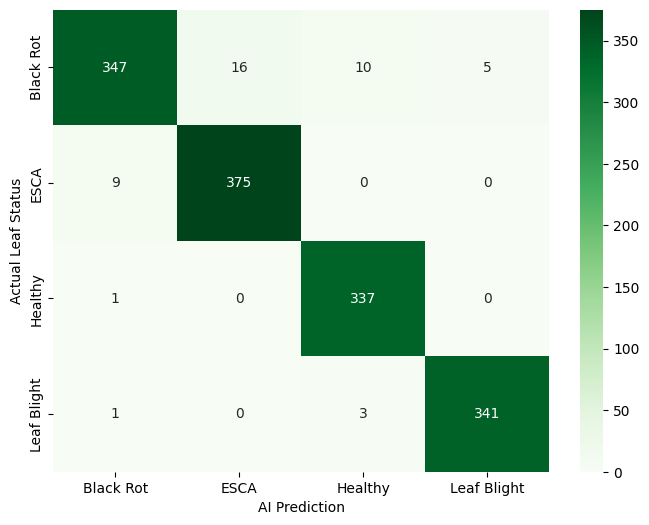

In [55]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

# The Matrix
cm = confusion_matrix(val_labels, val_preds)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', 
            xticklabels=full_train.classes, 
            yticklabels=full_train.classes)
plt.ylabel('Actual Leaf Status')
plt.xlabel('AI Prediction')
plt.show()


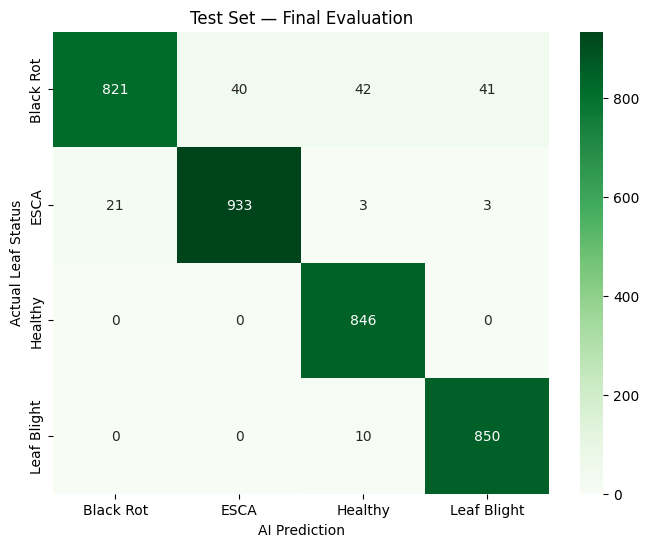

              precision    recall  f1-score   support

   Black Rot       0.98      0.87      0.92       944
        ESCA       0.96      0.97      0.97       960
     Healthy       0.94      1.00      0.97       846
 Leaf Blight       0.95      0.99      0.97       860

    accuracy                           0.96      3610
   macro avg       0.96      0.96      0.96      3610
weighted avg       0.96      0.96      0.95      3610



In [60]:
test_preds, test_labels_list = [], []

with torch.no_grad():
    for inputs, labels in test_loader:
        inputs = inputs.to(device)
        outputs = model(inputs)
        _, preds = torch.max(outputs, 1)
        test_preds.extend(preds.cpu().numpy())
        test_labels_list.extend(labels.cpu().numpy())

# Confusion matrix
cm = confusion_matrix(test_labels_list, test_preds)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens',
            xticklabels=full_train.classes,
            yticklabels=full_train.classes)
plt.ylabel('Actual Leaf Status')
plt.xlabel('AI Prediction')
plt.title('Test Set — Final Evaluation')
plt.show()

# Report
print(classification_report(test_labels_list, test_preds, target_names=full_train.classes))